# 05 · SNV — shared split for the six-modality fusion

This notebook re-runs the **SNV notebook's own method** (10 driver genes + batch-adjusted TMB, 11 qubits, 3 layers CZ brickwork, 5 seeds) on the **same site-held-out split and the same
5 site-grouped folds as the fusion notebook**, and saves out-of-fold (training) and test probabilities so the fusion
can be built directly on the per-modality models.

* **Split:** 7 test hospitals `12, 14, 27, CS, DU, QH, RY`; folds from `StratifiedGroupKFold(5, seed 42)` over the same
  cohort the fusion notebook builds (labels are read from all six files). The split hash printed below must be the
  same in all six notebooks.
* **Leakage:** every supervised step (feature selection, graph, scaling, training) is refitted inside each fold and once
  on all training patients for the test set. The notebook's hyperparameters are **frozen** (no search is re-run).
* **Models saved:** `VQC` (this modality's circuit), `LRm` (logistic regression on the same features, matched classical
  baseline), `LR` (tuned logistic regression, identical to the fusion notebook), `LR_LGG` (LGG-only model for
  hierarchical fusion).
* **Output:** `probs_snv.csv`, `info_snv.json`, `split_shared.csv`.
  Add this notebook's output as an input of the fusion notebook.

Runtime on a Kaggle CPU session: ≈ 4–8 min.

In [56]:
# ============================================================
# 0. IMPORTS
# ============================================================
import os
os.environ["PYTHONWARNINGS"] = "ignore"
import re, csv, time, json, hashlib, warnings, urllib.request
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.covariance import LedoitWolf
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import f1_score, classification_report

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
csv.field_size_limit(2**31 - 1)
try:
    display
except NameError:
    display = print
T_START = time.time()

In [57]:
# ============================================================
# 1. CONFIGURATION  (paths and split are identical to the fusion notebook)
# ============================================================
MODALITY = "snv"

FILES = {
    "proteomics":      "/kaggle/input/datasets/devipriyabala/unbalanced/proteomics_matrix.csv",
    "methylation":     "/kaggle/input/datasets/devipriyabala/unbalanced/methylation_matrix.csv",
    "gene_expression": "/kaggle/input/datasets/devipriyabala/unbalanced/gene_expr_matrix.csv",
    "mirna":           "/kaggle/input/datasets/devipriyabala/unbalanced/mirna_matrix.csv",
    "snv":             "/kaggle/input/datasets/nirupamas1746/snv-dataset/snv1.csv",
    "cnv":             "/kaggle/input/datasets/nirupamas1746/cnv-fixed/cnv_fixed.csv",
}
for _m in FILES:                                   # optional overrides, e.g. CNV_FILE=...
    FILES[_m] = os.environ.get(f"{_m.upper()}_FILE", FILES[_m])
missing_files = [p for p in FILES.values() if not os.path.exists(p)]
assert not missing_files, f"File(s) not found: {missing_files} (all six are needed to build the shared split)"
OUTPUT_DIR = os.environ.get("OUTPUT_DIR", "/kaggle/working" if os.path.isdir("/kaggle/working") else ".")
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODALITIES = list(FILES)
SHORT_M = {"proteomics": "PROT", "methylation": "METH", "gene_expression": "GE", "mirna": "miRNA",
           "snv": "SNV", "cnv": "CNV"}
LABEL_COL = "subtype"
CLASSES = ["astrocytoma", "glioblastoma", "mixed_glioma", "oligodendroglioma"]
K = len(CLASSES)
GBM = "glioblastoma"
LGG = [c for c in CLASSES if c != GBM]

RANDOM_STATE = 42
TEST_SITES = ["12", "14", "27", "CS", "DU", "QH", "RY"]
OUTER_FOLDS, INNER_FOLDS = 5, 4
NA_STR = {"", "nan", "NaN", "NA", "na", "NULL", "null", "None"}
N_JOBS = -1                      # parallel workers for the 5 folds + final model (-1 = all CPUs)

# label-free preprocessing, fitted on training patients only (same as the fusion notebook)
PROT_SAMPLE_MISSING, PROT_MAX_MISSING = 0.20, 0.05
USE_PROBE_BLACKLIST = True
METH_PRESENT_PER_PLATFORM, METH_TOP_VAR, M_EPSILON = 0.90, 10000, 1e-3
GE_EXPR_MIN, GE_EXPR_FRAC, GE_TOP_VAR = 1.0, 0.20, 5000
MIRNA_DETECT_FRAC = 0.20
SNV_MIN_FREQ = 0.02
SNV_DRIVERS = ["EGFR", "PTEN", "NF1", "IDH1", "IDH2", "TP53", "ATRX", "CIC", "FUBP1", "NOTCH1"]
SNV_META = ["patient_folder", "Tumor_Sample_Barcode", "n_caller_files"]
TMB_BINS = 4
CNV_REGION_R = 0.90

# classical base learner (identical grid to the fusion notebook, so the LR results are reproduced)
BASE_GRIDS = {
    "proteomics":      {"sel__spec": [("anova", 15), ("anova", 30), ("anova", 60), ("hier", 5, 25)],
                        "clf__C": [0.03, 0.3, 1.0]},
    "methylation":     {"sel__spec": [("anova", 10), ("anova", 50), ("anova", 200), ("hier", 2, 10), ("hier", 10, 90)],
                        "clf__C": [0.01, 0.1, 1.0]},
    "gene_expression": {"sel__spec": [("anova", 10), ("anova", 50), ("anova", 200), ("hier", 2, 10), ("hier", 10, 90)],
                        "clf__C": [0.01, 0.1, 1.0]},
    "mirna":           {"sel__spec": [("anova", 10), ("anova", 30), ("anova", 100), ("hier", 5, 25)],
                        "clf__C": [0.03, 0.3]},
    "snv":             {"sel__spec": [("drivers",), ("drivers+anova", 20), ("anova", 50)],
                        "clf__C": [0.1, 1.0]},
    "cnv":             {"sel__spec": [("anova", 6), ("anova", 12), ("anova", 24), ("all",)],
                        "clf__C": [0.03, 0.3, 1.0]},
}

In [58]:
# ============================================================
# 2. SHARED SPLIT  (same cohort, same 7 test hospitals, same 5 site-grouped folds as the fusion notebook)
# Only the ID and label columns of the other files are read, so this takes about a minute.
# ============================================================
def pid(s):
    return str(s).strip().upper()[:12]


def read_table(path, keep_meta=()):
    """Read a patient x feature CSV. Returns (X numeric float32, labels, meta columns)."""
    t0 = time.time()
    try:
        import polars as pl
        d = pl.read_csv(path, infer_schema_length=1000, null_values=sorted(NA_STR), ignore_errors=True).to_pandas()
    except Exception as e:
        print(f"  polars unavailable/failed ({type(e).__name__}) -> pandas")
        d = pd.read_csv(path, low_memory=False, na_values=sorted(NA_STR))
    idcol = d.columns[0]
    d.index = d[idcol].map(pid)
    lab = d[LABEL_COL].astype(str).str.strip() if LABEL_COL in d.columns else None
    meta = d[[c for c in keep_meta if c in d.columns]].copy()
    drop = [idcol] + ([LABEL_COL] if LABEL_COL in d.columns else []) + list(meta.columns)
    X = d.drop(columns=drop)
    num = X.select_dtypes(include=[np.number]).columns
    X = X[num].astype(np.float32)
    dup = X.index.duplicated()
    if dup.any():
        X, meta = X[~dup], meta[~dup]
        lab = lab[~dup] if lab is not None else None
    print(f"  {path.split('/')[-1]}: {X.shape[0]} patients x {X.shape[1]:,} features ({time.time() - t0:.0f}s)")
    return X, lab, meta


def fast_labels(path):
    """patient -> label, reading only the first column and the label column of each line."""
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        header = next(csv.reader([f.readline()]))
        li = header.index(LABEL_COL) if LABEL_COL in header else len(header) - 1
        last = li == len(header) - 1
        ids, labs = [], []
        for line in f:
            line = line.rstrip("\r\n")
            if not line:
                continue
            if '"' in line:
                row = next(csv.reader([line])); ids.append(row[0]); labs.append(row[li])
            elif last:
                ids.append(line.split(",", 1)[0]); labs.append(line.rsplit(",", 1)[1])
            else:
                row = line.split(","); ids.append(row[0]); labs.append(row[li])
    s = pd.Series([str(v).strip() for v in labs], index=[pid(i) for i in ids])
    return s[~s.index.duplicated()]


t0 = time.time()
RAW, LABELS, META = {}, {}, {}
print("proteomics (full read: old-panel samples are removed exactly as in the fusion notebook)")
RAW["proteomics"], LABELS["proteomics"], META["proteomics"] = read_table(FILES["proteomics"])
_old = RAW["proteomics"].isna().mean(axis=1) > PROT_SAMPLE_MISSING
print(f"  old-panel samples removed: {int(_old.sum())}")
RAW["proteomics"], LABELS["proteomics"] = RAW["proteomics"][~_old], LABELS["proteomics"][~_old]
for m in MODALITIES:
    if m != "proteomics":
        LABELS[m] = fast_labels(FILES[m])
        print(f"  {m}: {len(LABELS[m])} patients (labels only)")

all_pat = sorted(set().union(*[set(LABELS[m].index) for m in MODALITIES]))
lab_tab = pd.DataFrame({m: LABELS[m].reindex(all_pat) for m in MODALITIES}, index=all_pat)
conflict = lab_tab.index[lab_tab.nunique(axis=1) > 1]
cohort = pd.DataFrame(index=pd.Index([p for p in all_pat if p not in set(conflict)], name="patient"))
cohort["subtype"] = lab_tab.loc[cohort.index].bfill(axis=1).iloc[:, 0]
cohort = cohort[cohort["subtype"].isin(CLASSES)]
for m in MODALITIES:
    cohort[m] = cohort.index.isin(LABELS[m].index)
cohort["site"] = [p.split("-")[1] for p in cohort.index]
cohort["split"] = np.where(cohort["site"].isin(TEST_SITES), "test", "train")
TRAIN = cohort.index[cohort["split"] == "train"]
TEST = cohort.index[cohort["split"] == "test"]

FOLD = pd.Series(-1, index=TRAIN)
sgk = StratifiedGroupKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
for k, (_, va) in enumerate(sgk.split(np.zeros(len(TRAIN)), cohort.loc[TRAIN, "subtype"], cohort.loc[TRAIN, "site"])):
    FOLD.iloc[va] = k
cohort["fold"] = FOLD.reindex(cohort.index).fillna(-1).astype(int)
SPLIT_HASH = hashlib.sha1("|".join(f"{p}:{s}:{f}" for p, s, f in
                                   zip(cohort.index, cohort["split"], cohort["fold"])).encode()).hexdigest()[:12]
cohort.rename(columns={m: f"has_{m}" for m in MODALITIES}).to_csv(os.path.join(OUTPUT_DIR, "split_shared.csv"))
print(f"\nPatients {len(cohort)} | train {len(TRAIN)} | test {len(TEST)} | split hash {SPLIT_HASH} "
      f"| {time.time() - t0:.0f}s")
print("Fold sizes:", FOLD.value_counts().sort_index().to_dict())
if MODALITY != "proteomics":
    del RAW["proteomics"]

proteomics (full read: old-panel samples are removed exactly as in the fusion notebook)
  proteomics_matrix.csv: 332 patients x 465 features (0s)
  old-panel samples removed: 14
  methylation: 426 patients (labels only)
  gene_expression: 436 patients (labels only)
  mirna: 413 patients (labels only)
  snv: 436 patients (labels only)
  cnv: 424 patients (labels only)

Patients 439 | train 315 | test 124 | split hash f3ea2f6bb5ee | 10s
Fold sizes: {0: 100, 1: 96, 2: 85, 3: 12, 4: 22}


In [59]:
# ============================================================
# 3. PREPROCESSING (same as the fusion notebook; TMB levels are recomputed inside each fold for the VQC)
# ============================================================
RAW["snv"], _, META["snv"] = read_table(FILES["snv"], keep_meta=SNV_META)
S = RAW.pop("snv")
S = S.loc[cohort.index.intersection(S.index)]
B = (S.fillna(0) > 0).astype(np.float32)
TMB_LOG = np.log1p(B.sum(axis=1))
tr = TRAIN.intersection(B.index)
freq = B.loc[tr].mean()
drivers = [g for g in SNV_DRIVERS if g in B.columns]
if len(drivers) < len(SNV_DRIVERS):
    print("driver genes not found in the SNV table:", sorted(set(SNV_DRIVERS) - set(drivers)))
cols = sorted(set(freq.index[freq >= SNV_MIN_FREQ]) | set(drivers))
XM = B[cols].copy()
mcol = META["snv"]
HAS_CALLER = "n_caller_files" in mcol.columns
if HAS_CALLER:
    MULTI = (pd.to_numeric(mcol["n_caller_files"], errors="coerce").reindex(XM.index).fillna(1) >= 2).astype(int)


def tmb_level(fit_ids):
    """batch-adjusted TMB (log1p minus the training median of the caller group) -> 4 levels in [0, 1]."""
    adj = TMB_LOG.copy()
    for g in [0, 1]:
        ref = TMB_LOG[fit_ids][MULTI[fit_ids] == g]
        adj[MULTI == g] = TMB_LOG[MULTI == g] - (ref.median() if len(ref) else TMB_LOG[fit_ids].median())
    edges = np.quantile(adj[fit_ids], np.linspace(0, 1, TMB_BINS + 1)[1:-1])
    return pd.Series(np.searchsorted(edges, adj.values, side="right") / (TMB_BINS - 1), index=adj.index)


if HAS_CALLER:
    XM["TMB_batch_adjusted"] = tmb_level(tr).astype(np.float32)
else:
    print("no 'n_caller_files' column -> TMB left out")
SNV_FIXED = drivers + (["TMB_batch_adjusted"] if HAS_CALLER else [])
print(f"snv: {XM.shape} | VQC features: {SNV_FIXED}")

  snv1.csv: 436 patients x 12,749 features (3s)
snv: (436, 159) | VQC features: ['EGFR', 'PTEN', 'NF1', 'IDH1', 'IDH2', 'TP53', 'ATRX', 'CIC', 'FUBP1', 'NOTCH1', 'TMB_batch_adjusted']


In [60]:
# ============================================================
# 4. CLASSICAL BASE LEARNER (same as the fusion notebook) + LGG-only model for hierarchical fusion
# ============================================================
SNV_FIXED = globals().get("SNV_FIXED", [])


def _topk(Xa, ya, k):
    if k <= 0 or len(np.unique(ya)) < 2:
        return []
    F = np.nan_to_num(f_classif(Xa, ya)[0], nan=-1.0, posinf=-1.0)
    return list(np.argsort(-F)[:k])


class Select(BaseEstimator, TransformerMixin):
    """Supervised column selector, fitted only on the data passed to fit()."""
    def __init__(self, spec=("anova", 30), names=None, fixed=None):
        self.spec, self.names, self.fixed = spec, names, fixed

    def fit(self, Xa, y):
        Xa, y = np.asarray(Xa, float), np.asarray(y)
        kind, n = self.spec[0], Xa.shape[1]
        fixed = [i for i, c in enumerate(self.names or []) if c in set(self.fixed or [])]
        if kind == "all":
            idx = list(range(n))
        elif kind == "anova":
            idx = _topk(Xa, y, min(self.spec[1], n))
        elif kind == "hier":
            lg = y != GBM
            idx = _topk(Xa, (y == GBM).astype(int), self.spec[1]) + _topk(Xa[lg], y[lg], self.spec[2])
        elif kind == "drivers":
            idx = fixed
        elif kind == "drivers+anova":
            rest = [i for i in range(n) if i not in set(fixed)]
            idx = fixed + [rest[j] for j in _topk(Xa[:, rest], y, self.spec[1])]
        else:
            raise ValueError(self.spec)
        self.idx_ = np.array(sorted(set(idx)) or [0])
        return self

    def transform(self, Xa):
        return np.asarray(Xa)[:, self.idx_]


def make_base_pipe():
    return Pipeline([
        ("imp", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("sc", StandardScaler()),
        ("sel", Select(names=list(XM.columns), fixed=SNV_FIXED if MODALITY == "snv" else None)),
        ("sc2", StandardScaler()),
        ("clf", LogisticRegression(max_iter=5000, class_weight="balanced")),
    ])


def tune_base(ids, seed):
    grid = dict(BASE_GRIDS[MODALITY])
    if MODALITY == "snv" and not SNV_FIXED:
        grid["sel__spec"] = [s for s in grid["sel__spec"] if s[0] == "anova"]
    gs = GridSearchCV(make_base_pipe(), grid, scoring="f1_macro", n_jobs=-1, refit=True, error_score="raise",
                      cv=StratifiedGroupKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=seed))
    gs.fit(XM.loc[ids], cohort.loc[ids, "subtype"], groups=cohort.loc[ids, "site"])
    return gs


def proba_df(model, Xd, classes=CLASSES):
    p = model.predict_proba(Xd)
    out = pd.DataFrame(0.0, index=Xd.index, columns=classes)
    for j, c in enumerate(model.classes_):
        out[c] = p[:, j]
    return out


def y_idx(ids):
    return np.array([CLASSES.index(c) for c in cohort.loc[ids, "subtype"]])


def matched_lr(F_fit, y_fit, F_pred):
    """Classical baseline on exactly the VQC's input features."""
    lr = Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=5000, class_weight="balanced"))])
    lr.fit(F_fit, y_fit)
    p = np.zeros((len(F_pred), K)); p[:, lr.classes_] = lr.predict_proba(F_pred)
    return p

In [61]:
# ============================================================
# 5a. EXACT STATEVECTOR SIMULATOR (NumPy, adjoint gradients) + hybrid VQC trainer
# ============================================================
class QSim:
    """Exact batched statevector simulator (noise-free) with exact adjoint gradients.
    Basis index = sum_q bit_q * 2**q. Ops (applied in order):
      ("ry_x", q, col) / ("rx_x", q, col)  data rotation, angle = A[:, col]
      ("zz_x", q1, q2, col)                data IsingZZ = exp(-i a/2 Z(q1)Z(q2)), a = A[:, col]
      ("ry", q, k) / ("rz", q, k)          trainable rotation, angle = theta[k]
      ("cnot", c, t) / ("cz", c, t)        fixed entangling gates
    Observables: tuples of qubits, e.g. (0,) = <Z0>, (0, 3) = <Z0 Z3> (all diagonal)."""
    def __init__(self, n, ops, observables):
        self.n, self.D, self.ops = n, 2 ** n, list(ops)
        idx = np.arange(self.D)
        bits = (idx[None, :] >> np.arange(n)[:, None]) & 1                    # (n, D)
        self.zsign = (1 - 2 * bits).astype(float)
        self._perm, self._cz = {}, {}
        for op in self.ops:
            if op[0] == "cnot":
                c, t = op[1], op[2]
                self._perm[(c, t)] = np.where((idx >> c) & 1, idx ^ (1 << t), idx)
            elif op[0] == "cz":
                c, t = op[1], op[2]
                self._cz[(c, t)] = np.where(((idx >> c) & 1) & ((idx >> t) & 1), -1.0, 1.0)
        self.O = np.array([np.prod([self.zsign[q] for q in obs], axis=0) for obs in observables])   # (n_obs, D)
        self.n_params = 1 + max([op[2] for op in self.ops if op[0] in ("ry", "rz")], default=-1)

    def _1q(self, psi, q, a, b, c, d):
        B = psi.shape[0]
        v = psi.reshape(B, -1, 2, 1 << q)
        a0, a1 = v[:, :, 0, :], v[:, :, 1, :]
        o = np.empty_like(v)
        o[:, :, 0, :] = a * a0 + b * a1
        o[:, :, 1, :] = c * a0 + d * a1
        return o.reshape(B, -1)

    @staticmethod
    def _col(t):
        t = np.asarray(t, float)
        return t[:, None, None] if t.ndim else t

    def _ry(self, psi, q, t):
        t = self._col(t); c, s = np.cos(t / 2), np.sin(t / 2)
        return self._1q(psi, q, c, -s, s, c)

    def _rx(self, psi, q, t):
        t = self._col(t); c, s = np.cos(t / 2), np.sin(t / 2)
        return self._1q(psi, q, c, -1j * s, -1j * s, c)

    def _diag(self, psi, t, sign):
        t = np.asarray(t, float)
        return psi * np.exp(-0.5j * (t[:, None] if t.ndim else t) * sign[None, :])

    def _apply(self, psi, op, A, th, inv=False):
        k, s = op[0], (-1.0 if inv else 1.0)
        if k == "ry_x": return self._ry(psi, op[1], s * A[:, op[2]])
        if k == "rx_x": return self._rx(psi, op[1], s * A[:, op[2]])
        if k == "zz_x": return self._diag(psi, s * A[:, op[3]], self.zsign[op[1]] * self.zsign[op[2]])
        if k == "ry":   return self._ry(psi, op[1], s * th[op[2]])
        if k == "rz":   return self._diag(psi, s * th[op[2]], self.zsign[op[1]])
        if k == "cnot": return psi[:, self._perm[(op[1], op[2])]]
        if k == "cz":   return psi * self._cz[(op[1], op[2])]
        raise ValueError(k)

    def state(self, A, th):
        psi = np.zeros((A.shape[0], self.D), complex); psi[:, 0] = 1.0
        for op in self.ops:
            psi = self._apply(psi, op, A, th)
        return psi

    def expect(self, psi):
        return (psi.real ** 2 + psi.imag ** 2) @ self.O.T                     # (B, n_obs)

    def grad(self, A, th, psi, G):
        """d/dtheta of sum_b sum_k G[b, k] <O_k>_b (adjoint method)."""
        phi, lam = psi, psi * (G @ self.O)
        g = np.zeros(self.n_params)
        for op in reversed(self.ops):
            phi = self._apply(phi, op, A, th, inv=True)                      # state before this gate
            if op[0] == "ry":
                t = th[op[2]]; c, s = np.cos(t / 2) / 2, np.sin(t / 2) / 2
                mu = self._1q(phi, op[1], -s, -c, c, -s)
                g[op[2]] += 2.0 * np.real(np.vdot(lam, mu))
            elif op[0] == "rz":
                mu = -0.5j * self.zsign[op[1]][None, :] * self._apply(phi, op, A, th)
                g[op[2]] += 2.0 * np.real(np.vdot(lam, mu))
            lam = self._apply(lam, op, A, th, inv=True)
        return g


def _softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)


class HybridVQC:
    """Circuit -> observables -> linear layer -> softmax, class-weighted cross-entropy.
    Optimisers follow the PyTorch update rules (Adam / RMSprop, weight decay added to the gradient)."""
    def __init__(self, sim, n_classes=4, optimizer="adam", lr=0.05, weight_decay=0.0, epochs=30, batch=32,
                 init_std=0.1, head_init="torch", schedule=None, seed=0, patience=None):
        self.sim, self.C = sim, n_classes
        self.opt, self.lr, self.wd, self.epochs, self.batch = optimizer, lr, weight_decay, epochs, batch
        self.init_std, self.head_init, self.schedule, self.seed, self.patience = init_std, head_init, schedule, seed, patience

    def _forward(self, A, P):
        th, W, b = P
        psi = self.sim.state(A, th); z = self.sim.expect(psi)
        return psi, z, z @ W.T + b

    def _loss(self, A, y, w, P):
        _, _, lg = self._forward(A, P)
        p = _softmax(lg); ww = w[y]
        return float(-(ww * np.log(p[np.arange(len(y)), y] + 1e-12)).sum() / ww.sum())

    def fit(self, A, y, A_val=None, y_val=None):
        rng = np.random.default_rng(self.seed)
        y = np.asarray(y); n_obs = self.sim.O.shape[0]
        th = rng.normal(0, self.init_std, self.sim.n_params)
        if self.head_init == "torch":
            bd = 1 / np.sqrt(n_obs)
            W, b = rng.uniform(-bd, bd, (self.C, n_obs)), rng.uniform(-bd, bd, self.C)
        else:
            W, b = rng.normal(0, self.init_std, (self.C, n_obs)), np.zeros(self.C)
        P = [th, W, b]
        cnt = np.bincount(y, minlength=self.C)
        w = len(y) / (self.C * np.maximum(cnt, 1))
        m1 = [np.zeros_like(p) for p in P]; m2 = [np.zeros_like(p) for p in P]; t = 0
        best, best_P, wait = np.inf, None, 0
        for ep in range(self.epochs):
            lr = self.lr * (self.schedule(ep) if self.schedule else 1.0)
            order = rng.permutation(len(y))
            bs = len(y) if self.batch in (None, "full") else self.batch
            for s0 in range(0, len(y), bs):
                bi = order[s0:s0 + bs]
                psi, z, lg = self._forward(A[bi], P)
                p = _softmax(lg); ww = w[y[bi]]
                dl = ww[:, None] * (p - np.eye(self.C)[y[bi]]) / ww.sum()
                grads = [self.sim.grad(A[bi], P[0], psi, dl @ P[1]), dl.T @ z, dl.sum(0)]
                t += 1
                for i, g in enumerate(grads):
                    if self.wd: g = g + self.wd * P[i]
                    if self.opt == "adam":
                        m1[i] = 0.9 * m1[i] + 0.1 * g; m2[i] = 0.999 * m2[i] + 0.001 * g * g
                        P[i] = P[i] - lr * (m1[i] / (1 - 0.9 ** t)) / (np.sqrt(m2[i] / (1 - 0.999 ** t)) + 1e-8)
                    elif self.opt == "rmsprop":
                        m2[i] = 0.99 * m2[i] + 0.01 * g * g
                        P[i] = P[i] - lr * g / (np.sqrt(m2[i]) + 1e-8)
                    else:
                        raise ValueError(self.opt)
            if A_val is not None:
                vl = self._loss(A_val, np.asarray(y_val), w, P)
                if vl < best - 1e-4:
                    best, best_P, wait = vl, [p.copy() for p in P], 0
                else:
                    wait += 1
                    if self.patience and wait >= self.patience:
                        break
        self.P_ = best_P if best_P is not None else P
        self.n_params_ = self.sim.n_params + W.size + b.size
        return self

    def predict_proba(self, A):
        out = []
        for s0 in range(0, len(A), 256):
            out.append(_softmax(self._forward(A[s0:s0 + 256], self.P_)[2]))
        return np.vstack(out)



def _gradcheck():
    rng = np.random.default_rng(0)
    ops = [("ry_x", 0, 0), ("ry_x", 1, 1), ("ry_x", 2, 2), ("zz_x", 0, 1, 3), ("ry", 0, 0), ("rz", 1, 1),
           ("ry", 2, 2), ("cnot", 0, 1), ("cz", 1, 2), ("rz", 0, 3), ("ry", 1, 4)]
    s = QSim(3, ops, [(0,), (1,), (2,), (0, 2)])
    A, th, G = rng.uniform(0, 3, (4, 4)), rng.normal(size=s.n_params), rng.normal(size=(4, 4))
    g = s.grad(A, th, s.state(A, th), G)
    f = lambda t: (G * s.expect(s.state(A, t))).sum()
    fd = np.array([(f(th + e) - f(th - e)) / 2e-6 for e in np.eye(len(th)) * 1e-6])
    return np.abs(g - fd).max()


print(f"adjoint vs finite-difference gradient, max diff: {_gradcheck():.1e}")

adjoint vs finite-difference gradient, max diff: 2.2e-10


In [62]:
# ============================================================
# 5b. SNV VQC (SNV notebook's circuit; commuting gates merged -> identical outputs, ~3x faster): 10 driver genes + batch-adjusted TMB (levels recomputed on each
# fold's training patients) = 11 qubits; RY(pi x) re-uploaded before each of 3 layers of RY+RZ + CZ brickwork;
# <Z> -> linear -> softmax; full-batch Adam lr 0.08, 45 epochs, 5-seed ensemble.
# ============================================================
N_LAYERS, REUPLOAD = 3, True
EPOCHS, LEARNING_RATE, INIT_STD = 45, 0.08, 0.1
SNV_SEEDS = [11, 22, 33, 44, 55]
VQC_SETTINGS = dict(selector="10 literature driver genes + batch-adjusted TMB", layers=N_LAYERS, encoding="RY(pi x) re-uploaded",
                    entangler="CZ brickwork", readout="<Z> -> linear", optimizer="Adam (full batch)", lr=LEARNING_RATE,
                    epochs=EPOCHS, seeds=SNV_SEEDS)


class FastVQC:
    """Same circuit as the SNV notebook (per layer: RY(pi x) re-upload, RY(theta)+RZ(phi) on every qubit, CZ brickwork),
    with gates that commute merged: RY(pi x) RY(theta) = RY(pi x + theta), and all RZ + CZ of a layer = one diagonal.
    Identical outputs and exact adjoint gradients, ~3x fewer passes over the state."""
    def __init__(self, n, layers=N_LAYERS, reupload=REUPLOAD):
        self.n, self.dim, self.L, self.reupload = n, 2 ** n, layers, reupload
        bits = (np.arange(self.dim)[:, None] >> np.arange(n)) & 1
        self.zsign = (1 - 2 * bits).astype(float)                      # (dim, n)
        self.pairs = [(q, q + 1) for q in range(0, n - 1, 2)] + [(q, q + 1) for q in range(1, n - 1, 2)]
        cz = np.ones(self.dim)
        for c, t in self.pairs:
            cz *= np.where(bits[:, c] & bits[:, t], -1.0, 1.0)
        self.cz = cz
        self.n_params = 2 * n * layers                                 # th[2*(l*n+q)] = RY, th[2*(l*n+q)+1] = RZ

    def _ap(self, psi, a, b, c, d, q):
        B = psi.shape[0]
        v = psi.reshape(B, -1, 2, 1 << q)
        a0, a1 = v[:, :, 0, :], v[:, :, 1, :]
        o = np.empty_like(v)
        o[:, :, 0, :] = a * a0 + b * a1
        o[:, :, 1, :] = c * a0 + d * a1
        return o.reshape(B, -1)

    def _ry(self, psi, t, q):
        c, s = np.cos(t / 2)[:, None, None], np.sin(t / 2)[:, None, None]
        return self._ap(psi, c, -s, s, c, q)

    def _angles(self, Xa, th, l):
        enc = Xa if (l == 0 or self.reupload) else np.zeros_like(Xa)
        return enc + th[2 * l * self.n:2 * (l + 1) * self.n:2][None, :]           # (B, n)

    def _diag(self, th, l):
        phi = th[2 * l * self.n + 1:2 * (l + 1) * self.n:2]
        return np.exp(-0.5j * (self.zsign @ phi)) * self.cz

    def state(self, Xa, th):
        psi = np.zeros((len(Xa), self.dim), complex); psi[:, 0] = 1
        for l in range(self.L):
            T = self._angles(Xa, th, l)
            for q in range(self.n):
                psi = self._ry(psi, T[:, q], q)
            psi = psi * self._diag(th, l)[None, :]
        return psi

    def expz(self, psi):
        return (np.abs(psi) ** 2) @ self.zsign

    def grad(self, Xa, th, psi, G):
        phi, lam = psi.copy(), psi * (G @ self.zsign.T)
        g = np.zeros(self.n_params)
        for l in reversed(range(self.L)):
            g[2 * l * self.n + 1:2 * (l + 1) * self.n:2] = np.imag(np.conj(lam) * phi).sum(0) @ self.zsign
            dc = np.conj(self._diag(th, l))[None, :]
            phi, lam = phi * dc, lam * dc
            T = self._angles(Xa, th, l)
            for q in reversed(range(self.n)):
                t = T[:, q]
                phi = self._ry(phi, -t, q)
                c, s = (np.cos(t / 2) / 2)[:, None, None], (np.sin(t / 2) / 2)[:, None, None]
                mu = self._ap(phi, -s, -c, c, -s, q)
                g[2 * (l * self.n + q)] = 2.0 * np.real(np.vdot(lam, mu))
                lam = self._ry(lam, -t, q)
        return g


def unique_patterns(A):
    u, inv = np.unique(A, axis=0, return_inverse=True)
    return u.astype(float), np.asarray(inv).ravel()


def train_snv(F_tr, y_tr, F_te, seed):
    eng = FastVQC(F_tr.shape[1])
    rng = np.random.default_rng(seed)
    Xu, inv = unique_patterns(F_tr); Xa = Xu * np.pi
    N = len(y_tr)
    sw = (N / (K * np.bincount(y_tr, minlength=K)))[y_tr][:, None]
    Yo = np.eye(K)[y_tr]
    q = rng.normal(0, INIT_STD, eng.n_params)
    W = rng.normal(0, INIT_STD, (K, eng.n)); b = np.zeros(K)
    P = [q, W, b]; m = [np.zeros_like(p) for p in P]; v = [np.zeros_like(p) for p in P]
    for ep in range(1, EPOCHS + 1):
        psi = eng.state(Xa, q)
        Zu = eng.expz(psi); Z = Zu[inv]
        pr = _softmax(Z @ W.T + b)
        dl = sw * (pr - Yo) / N
        dZu = np.zeros_like(Zu); np.add.at(dZu, inv, dl @ W)
        for i, g in enumerate([eng.grad(Xa, q, psi, dZu), dl.T @ Z, dl.sum(0)]):
            m[i] = 0.9 * m[i] + 0.1 * g
            v[i] = 0.999 * v[i] + 0.001 * g * g
            P[i] -= LEARNING_RATE * (m[i] / (1 - 0.9 ** ep)) / (np.sqrt(v[i] / (1 - 0.999 ** ep)) + 1e-8)
    Xu_te, inv_te = unique_patterns(F_te)
    return _softmax(eng.expz(eng.state(Xu_te * np.pi, q))[inv_te] @ W.T + b), eng.n_params + W.size + b.size


def run_quantum(fit_ids, pred_ids, tag):
    y = y_idx(fit_ids)
    feats = list(drivers)
    Ff, Fp = XM.loc[fit_ids, feats].values.astype(float), XM.loc[pred_ids, feats].values.astype(float)
    if HAS_CALLER:
        lev = tmb_level(fit_ids)
        Ff = np.column_stack([Ff, lev.loc[fit_ids].values]); Fp = np.column_stack([Fp, lev.loc[pred_ids].values])
        feats = feats + ["TMB_batch_adjusted"]
    out = [train_snv(Ff, y, Fp, s) for s in SNV_SEEDS]
    return {"VQC": pd.DataFrame(np.mean([o[0] for o in out], 0), index=pred_ids, columns=CLASSES),
            "LRm": pd.DataFrame(matched_lr(Ff, y, Fp), index=pred_ids, columns=CLASSES),
            "features": feats, "n_params": out[0][1]}

In [63]:
# ============================================================
# 6. OUT-OF-FOLD (training) AND TEST PROBABILITIES
# fold k: every model is fitted on training patients outside fold k and predicts fold k;
# final: fitted on all training patients, predicts the test patients.
# ============================================================
ids = TRAIN.intersection(XM.index)
te_ids = TEST.intersection(XM.index)
jobs = [(k, ids[FOLD.loc[ids].values != k], ids[FOLD.loc[ids].values == k]) for k in range(OUTER_FOLDS)]
jobs.append(("final", ids, te_ids))

t0 = time.time()
QOUT = Parallel(n_jobs=N_JOBS)(delayed(run_quantum)(fit, pred, str(tag)) for tag, fit, pred in jobs)
print(f"VQC + matched LR: {len(jobs)} fits in {(time.time() - t0) / 60:.1f} min")

t0 = time.time()
LR_OUT, LGG_OUT, LR_PARAMS = [], [], []
for tag, fit, pred in jobs:
    seed = RANDOM_STATE + (tag if tag != "final" else 0)
    gs = tune_base(fit, seed); LR_PARAMS.append({str(k): (list(v) if isinstance(v, tuple) else v)
                                                 for k, v in gs.best_params_.items()})
    LR_OUT.append(proba_df(gs, XM.loc[pred]))
    gl = tune_base(fit[(cohort.loc[fit, "subtype"] != GBM).values], seed)
    LGG_OUT.append(proba_df(gl, XM.loc[pred], LGG))
print(f"Logistic regression (tuned) + LGG-only model: {(time.time() - t0) / 60:.1f} min")

rows = []
for (tag, fit, pred), q, lr, lg in zip(jobs, QOUT, LR_OUT, LGG_OUT):
    st = "test" if tag == "final" else "oof"
    for name, P in [("LR", lr), ("VQC", q["VQC"]), ("LRm", q["LRm"]), ("LR_LGG", lg)]:
        d = P.reindex(columns=CLASSES).copy(); d.insert(0, "model", name); d.insert(0, "set", st)
        d.insert(0, "patient", d.index); rows.append(d.reset_index(drop=True))
PROBS = pd.concat(rows, ignore_index=True)
PROBS.to_csv(os.path.join(OUTPUT_DIR, f"probs_{MODALITY}.csv"), index=False)

VQC + matched LR: 6 fits in 8.7 min
Logistic regression (tuned) + LGG-only model: 0.1 min


In [64]:
# ============================================================
# 7. RESULTS + SAVED FILES
# ============================================================
def score(model, st):
    d = PROBS[(PROBS.model == model) & (PROBS.set == st)].set_index("patient")
    y = cohort.loc[d.index, "subtype"]; p = d[CLASSES].idxmax(axis=1)
    f = f1_score(y, p, labels=CLASSES, average=None, zero_division=0)
    return {"macro_f1": f1_score(y, p, labels=CLASSES, average="macro", zero_division=0), "n": len(d),
            **{f"F1_{c[:5]}": v for c, v in zip(CLASSES, f)}}


res = pd.DataFrame([{"model": m, "eval": e, **score(m, s)} for m in ["VQC", "LRm", "LR"]
                    for e, s in [("CV (out-of-fold)", "oof"), ("Test (7 held-out sites)", "test")]])
print(f"{MODALITY}: VQC = this modality's own feature selection + circuit | LRm = logistic regression on the same "
      f"features | LR = tuned logistic regression (fusion notebook grid)")
display(res.round(3))
fin = QOUT[-1]
print(f"\nFinal VQC: {len(fin['features'])} qubits, {fin['n_params']} trainable parameters")
print("Features (qubit order):", fin["features"])
fold_feats = [q["features"] for q in QOUT[:-1]]
from collections import Counter
print("Selection stability across the 5 folds:", dict(Counter(f for ff in fold_feats for f in ff).most_common(15)))
print("\n" + classification_report(cohort.loc[te_ids, "subtype"],
                                   PROBS[(PROBS.model == "VQC") & (PROBS.set == "test")].set_index("patient")
                                   .loc[te_ids, CLASSES].idxmax(axis=1), digits=3, zero_division=0))
info = {"modality": MODALITY, "split_hash": SPLIT_HASH, "n_train": int(len(ids)), "n_test": int(len(te_ids)),
        "final_params": LR_PARAMS[-1], "vqc_qubits": len(fin["features"]), "vqc_features": [str(f) for f in fin["features"]],
        "vqc_n_params": int(fin["n_params"]), "fold_features": [[str(f) for f in ff] for ff in fold_feats],
        "vqc_settings": VQC_SETTINGS, "results": res.round(4).to_dict(orient="records"),
        "runtime_min": round((time.time() - T_START) / 60, 1)}
json.dump(info, open(os.path.join(OUTPUT_DIR, f"info_{MODALITY}.json"), "w"), indent=1, default=str)
print(f"Saved: probs_{MODALITY}.csv, info_{MODALITY}.json, split_shared.csv"
      + (", meth_info.csv" if MODALITY == "methylation" else "") + f" -> {OUTPUT_DIR}")
print(f"Total runtime {(time.time() - T_START) / 60:.1f} min")

snv: VQC = this modality's own feature selection + circuit | LRm = logistic regression on the same features | LR = tuned logistic regression (fusion notebook grid)


,model,eval,macro_f1,n,F1_astro,F1_gliob,F1_mixed,F1_oligo
0,VQC,CV (out-of-fold),0.532,313,0.426,0.675,0.478,0.547
1,VQC,Test (7 held-out sites),0.555,123,0.444,0.643,0.448,0.683
2,LRm,CV (out-of-fold),0.515,313,0.409,0.650,0.464,0.536
3,LRm,Test (7 held-out sites),0.529,123,0.275,0.635,0.522,0.683
4,LR,CV (out-of-fold),0.520,313,0.407,0.658,0.458,0.557
5,LR,Test (7 held-out sites),0.510,123,0.275,0.635,0.478,0.651



Final VQC: 11 qubits, 114 trainable parameters
Features (qubit order): ['EGFR', 'PTEN', 'NF1', 'IDH1', 'IDH2', 'TP53', 'ATRX', 'CIC', 'FUBP1', 'NOTCH1', 'TMB_batch_adjusted']
Selection stability across the 5 folds: {'EGFR': 5, 'PTEN': 5, 'NF1': 5, 'IDH1': 5, 'IDH2': 5, 'TP53': 5, 'ATRX': 5, 'CIC': 5, 'FUBP1': 5, 'NOTCH1': 5, 'TMB_batch_adjusted': 5}

                   precision    recall  f1-score   support

      astrocytoma      0.467     0.424     0.444        33
     glioblastoma      0.500     0.900     0.643        30
     mixed_glioma      0.650     0.342     0.448        38
oligodendroglioma      0.737     0.636     0.683        22

         accuracy                          0.553       123
        macro avg      0.588     0.576     0.555       123
     weighted avg      0.580     0.553     0.537       123

Saved: probs_snv.csv, info_snv.json, split_shared.csv -> /kaggle/working
Total runtime 9.1 min


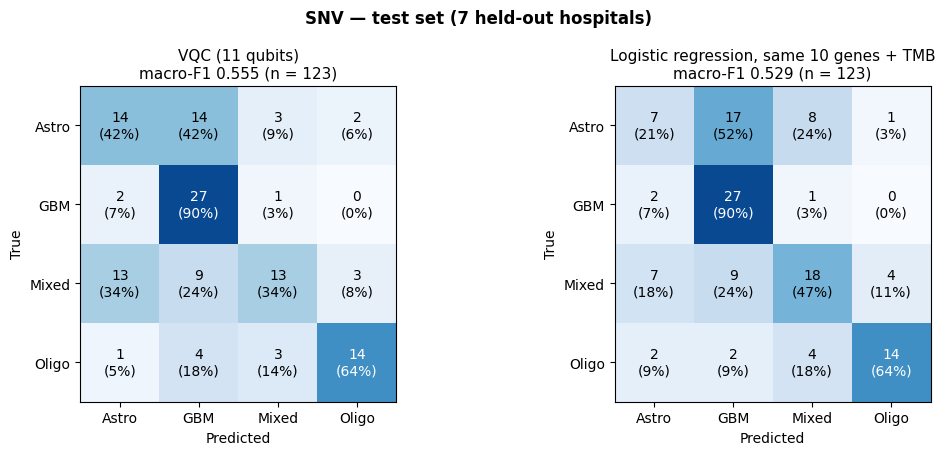

In [65]:
# ============================================================
# 8. CONFUSION MATRICES ON THE 7 HELD-OUT SITES (VQC vs matched LR)
# ============================================================
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score

SHORT = ["Astro", "GBM", "Mixed", "Oligo"]
y_true = cohort.loc[te_ids, "subtype"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (model, title) in zip(axes, [("VQC", "VQC (11 qubits)"), ("LRm", "Logistic regression, same 10 genes + TMB")]):
    P = PROBS[(PROBS.model == model) & (PROBS.set == "test")].set_index("patient").loc[te_ids, CLASSES]
    y_pred = P.idxmax(axis=1)
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    rec = cm / cm.sum(axis=1, keepdims=True).clip(min=1)               # row-normalised = recall per class
    ax.imshow(rec, cmap="Blues", vmin=0, vmax=1)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cm[i, j]}\n({rec[i, j]:.0%})", ha="center", va="center", fontsize=10,
                    color="white" if rec[i, j] > 0.55 else "black")
    ax.set_xticks(range(K), SHORT); ax.set_yticks(range(K), SHORT)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    mf1 = f1_score(y_true, y_pred, labels=CLASSES, average="macro", zero_division=0)
    ax.set_title(f"{title}\nmacro-F1 {mf1:.3f} (n = {len(y_true)})", fontsize=11)
fig.suptitle("SNV — test set (7 held-out hospitals)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "snv_confusion_matrix.png"), dpi=200, bbox_inches="tight")
plt.show()

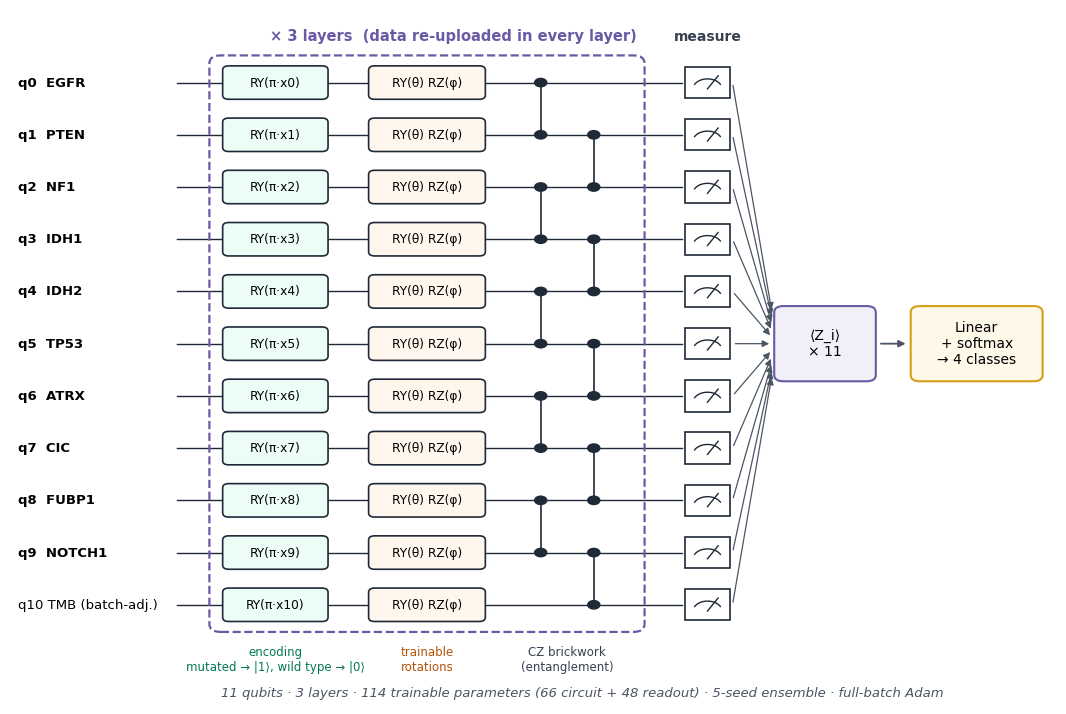

In [66]:
# ============================================================
# 9. VQC CIRCUIT DIAGRAM (final SNV model: 11 qubits, 3 re-uploading layers of
#    RY(pi x) + RY(theta) RZ(phi) on every qubit + CZ brickwork; <Z_i> readout)
# ============================================================
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, Circle

feats = [str(f) for f in QOUT[-1]["features"]]                      # 10 driver genes + TMB (qubit order)
feats = ["TMB (batch-adj.)" if f.startswith("TMB") else f for f in feats]
n = len(feats)
pairs1 = [(q, q + 1) for q in range(0, n - 1, 2)]
pairs2 = [(q, q + 1) for q in range(1, n - 1, 2)]
Y = lambda q: n - 1 - q
x_enc, x_rot, x_cz1, x_cz2 = 0.9, 2.9, 4.4, 5.1
x_end = x_cz2 + 0.5
x_meas = x_end + 1.0
fig, ax = plt.subplots(figsize=(13.5, 0.62 * n + 2.2))
ax.set_xlim(-2.6, x_meas + 4.6); ax.set_ylim(-1.9, n + 0.4); ax.axis("off")


def gate(x, y, text, fc, w=1.35):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - 0.3), w, 0.6, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec="#1f2937", lw=1.2, zorder=3))
    ax.text(x, y, text, ha="center", va="center", fontsize=8.8, zorder=4)


def meter(x, y):
    ax.add_patch(Rectangle((x - 0.3, y - 0.3), 0.6, 0.6, fc="white", ec="#1f2937", lw=1.2, zorder=3))
    th = np.linspace(np.pi * 0.15, np.pi * 0.85, 30)
    ax.plot(x + 0.19 * np.cos(th), y - 0.12 + 0.19 * np.sin(th), color="#1f2937", lw=1.0, zorder=4)
    ax.plot([x, x + 0.14], [y - 0.12, y + 0.13], color="#1f2937", lw=1.0, zorder=4)


for q in range(n):
    y = Y(q)
    ax.text(-2.5, y, f"q{q:<2d} {feats[q]}", ha="left", va="center", fontsize=9.5,
            fontweight="bold" if not feats[q].startswith("TMB") else "normal")
    ax.plot([-0.4, x_meas - 0.33], [y, y], color="#1f2937", lw=1.0, zorder=1)
    gate(x_enc, y, f"RY(π·x{q})", "#ecfdf5")
    gate(x_rot, y, "RY(θ) RZ(φ)", "#fff7ed", w=1.5)
    meter(x_meas, y)

for x, pairs in [(x_cz1, pairs1), (x_cz2, pairs2)]:                 # CZ brickwork
    for c, t in pairs:
        ax.plot([x, x], [Y(c), Y(t)], color="#1f2937", lw=1.2, zorder=2)
        for q in (c, t):
            ax.add_patch(Circle((x, Y(q)), 0.08, color="#1f2937", zorder=4))

ax.add_patch(FancyBboxPatch((x_enc - 0.85, -0.5), x_end - x_enc + 1.0, n,
                            boxstyle="round,pad=0.02,rounding_size=0.15", fc="none", ec="#6a5aa6", lw=1.6, ls="--"))
ax.text((x_enc + x_end) / 2, n - 0.2, "× 3 layers  (data re-uploaded in every layer)", ha="center",
        fontsize=10.5, color="#6a5aa6", fontweight="bold")
for x, t, col in [(x_enc, "encoding\nmutated → |1⟩, wild type → |0⟩", "#047857"),
                  (x_rot, "trainable\nrotations", "#b45309"),
                  ((x_cz1 + x_cz2) / 2, "CZ brickwork\n(entanglement)", "#374151")]:
    ax.text(x, -1.05, t, ha="center", va="center", fontsize=8.5, color=col)
ax.text(x_meas, n - 0.2, "measure", ha="center", fontsize=10, color="#374151", fontweight="bold")

xb = x_meas + 0.9
ax.add_patch(FancyBboxPatch((xb, (n - 1) / 2 - 0.7), 1.3, 1.4, boxstyle="round,pad=0.02,rounding_size=0.12",
                            fc="#f1eff8", ec="#6a5aa6", lw=1.5))
ax.text(xb + 0.65, (n - 1) / 2, f"⟨Z_i⟩\n× {n}", ha="center", va="center", fontsize=10)
ax.add_patch(FancyBboxPatch((xb + 1.8, (n - 1) / 2 - 0.7), 1.7, 1.4, boxstyle="round,pad=0.02,rounding_size=0.12",
                            fc="#fdf8e8", ec="#d4a017", lw=1.5))
ax.text(xb + 2.65, (n - 1) / 2, "Linear\n+ softmax\n→ 4 classes", ha="center", va="center", fontsize=10)
for q in range(n):
    ax.annotate("", xy=(xb - 0.05, (n - 1) / 2 + (Y(q) - (n - 1) / 2) * 0.12), xytext=(x_meas + 0.33, Y(q)),
                arrowprops=dict(arrowstyle="-|>", color="#4b5563", lw=0.9))
ax.annotate("", xy=(xb + 1.75, (n - 1) / 2), xytext=(xb + 1.35, (n - 1) / 2),
            arrowprops=dict(arrowstyle="-|>", color="#4b5563", lw=1.3))
nq = 3 * 2 * n
ax.text((x_enc + xb + 3.5) / 2 - 1, -1.75, f"{n} qubits · 3 layers · {QOUT[-1]['n_params']} trainable parameters "
        f"({nq} circuit + {QOUT[-1]['n_params'] - nq} readout) · 5-seed ensemble · full-batch Adam",
        ha="center", fontsize=9.5, color="#4b5563", style="italic")
plt.savefig(os.path.join(OUTPUT_DIR, "snv_vqc_circuit.png"), dpi=200, bbox_inches="tight")
plt.show()

In [67]:
# %% ---------------- CELL C0 — settings, helpers and model capture ----------------
import os, time, json, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
warnings.filterwarnings("ignore")

QUICK = False                   # True = fewer repeats / trajectories, for a first test run
RUN_FAKE_HARDWARE = True        # needs internet on (pip install qiskit qiskit-aer qiskit-ibm-runtime); circuits <= 7 qubits
LC_FRACS = [0.25, 0.5, 0.75, 1.0]
LC_REPEATS = 2 if QUICK else 3
SEED_REPEATS = 2 if QUICK else 4
NOISE_P = [0, 3e-4, 1e-3, 3e-3, 1e-2]          # depolarising prob. per 1-qubit gate; 2-qubit gates use 10 x p
N_TRAJ = 30 if QUICK else 100
SHOT_LEVELS = [256, 1024, 4096]
N_BOOT_C = 2000
C_DIR = os.path.join(OUTPUT_DIR, f"partC_{MODALITY}"); os.makedirs(C_DIR, exist_ok=True)
SITE = cohort["site"]

y_te = y_idx(te_ids)
mf1 = lambda y, p: f1_score(y, p, labels=list(range(K)), average="macro", zero_division=0)
_p = lambda model, st, idx: PROBS[(PROBS.model == model) & (PROBS.set == st)].set_index("patient").loc[idx, CLASSES].values
VQC_TEST, LRM_TEST, LR_TEST = _p("VQC", "test", te_ids), _p("LRm", "test", te_ids), _p("LR", "test", te_ids)
VQC_OOF = _p("VQC", "oof", ids)
FOLD_OF = FOLD.loc[ids].values


def paired(y, pa, pb, b=N_BOOT_C, seed=42):
    rng = np.random.default_rng(seed); d = []
    for _ in range(b):
        i = rng.integers(0, len(y), len(y)); d.append(mf1(y[i], pa[i]) - mf1(y[i], pb[i]))
    d = np.array(d); p = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))
    return float(d.mean()), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5)), max(p, 1.0 / b)


def ci(y, p, b=N_BOOT_C, seed=42):
    rng = np.random.default_rng(seed)
    v = [mf1(y[i], p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(b))]
    return float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))


# ---- capture: record the trained VQC objects and the exact VQC input features while run_quantum runs ----
CAP = {}


class Capture:
    """Temporarily wraps HybridVQC / QuantumClassifier / matched_lr so a run_quantum call leaves behind the trained
    model objects, their test inputs, and the feature matrices given to the matched logistic regression."""
    def __enter__(self):
        CAP.clear(); CAP.update(models=[], pred=[], lr=[]); g = globals(); self.saved = {}
        for cname in ["HybridVQC", "QuantumClassifier"]:
            if cname in g:
                C = g[cname]; self.saved[cname] = (C.fit, C.predict_proba)
                f0, p0 = C.fit, C.predict_proba
                def fit(m, *a, _f0=f0, **k):
                    r = _f0(m, *a, **k); CAP["models"].append(m); return r
                def pp(m, A, _p0=p0):
                    CAP["pred"].append((m, np.array(A, dtype=float))); return _p0(m, A)
                C.fit, C.predict_proba = fit, pp
        if "matched_lr" in g:
            self.saved["matched_lr"] = g["matched_lr"]; orig = g["matched_lr"]
            def mlr(F_fit, y_fit, F_pred, _o=orig):
                CAP["lr"].append((np.array(F_fit, float), np.array(y_fit), np.array(F_pred, float)))
                return _o(F_fit, y_fit, F_pred)
            g["matched_lr"] = mlr
        return self

    def __exit__(self, *a):
        g = globals()
        for cname in ["HybridVQC", "QuantumClassifier"]:
            if cname in self.saved:
                g[cname].fit, g[cname].predict_proba = self.saved[cname]
        if "matched_lr" in self.saved:
            g["matched_lr"] = self.saved["matched_lr"]


class NoEntangle:
    """Removes every entangling gate (CNOT, CZ, IsingZZ / RZZ) from this modality's circuit while active."""
    def __enter__(self):
        g = globals(); self.saved = {}
        if "QSim" in g:
            Q = g["QSim"]; self.saved["QSim"] = Q.__init__; i0 = Q.__init__
            def init(s, n, ops, observables, _i0=i0):
                _i0(s, n, [op for op in ops if op[0] not in ("cnot", "cz", "zz_x")], observables)
            Q.__init__ = init
        if "FastVQC" in g:
            F = g["FastVQC"]; self.saved["FastVQC"] = F.__init__; i1 = F.__init__
            def initf(s, *a, _i1=i1, **k):
                _i1(s, *a, **k); s.cz = np.ones_like(s.cz); s.pairs = []
            F.__init__ = initf
        if "QuantumClassifier" in g:
            C = g["QuantumClassifier"]; self.saved["QC"] = C._build; b0 = C._build
            def build(s, n, _b0=b0):
                ops, p = _b0(s, n); return [op for op in ops if op.kind not in ("cnot", "rzz")], p
            C._build = build
        return self

    def __exit__(self, *a):
        g = globals()
        if "QSim" in self.saved: g["QSim"].__init__ = self.saved["QSim"]
        if "FastVQC" in self.saved: g["FastVQC"].__init__ = self.saved["FastVQC"]
        if "QC" in self.saved: g["QuantumClassifier"]._build = self.saved["QC"]


HAS_ENTANGLERS = MODALITY != "methylation"
print(f"Part C for {MODALITY}: train {len(ids)} | test {len(te_ids)} | output {C_DIR}")



Part C for snv: train 313 | test 123 | output /kaggle/working/partC_snv


In [68]:
# %% ---------------- CELL C1 — re-run the VQC once with capture (features, trained models, timing) ----------------
FEATS, TIMES, FINAL_CAP = {}, {}, None
for tag, fit, pred in jobs:
    t0 = time.time()
    with Capture():
        out = run_quantum(fit, pred, str(tag))
    TIMES[str(tag)] = time.time() - t0
    if CAP["lr"]:
        F_fit, _, F_pred = CAP["lr"][-1]
    else:   # proteomics: same proteins, median imputation fitted on the training patients of this fit
        feats = out["features"]; imp = SimpleImputer(strategy="median", keep_empty_features=True).fit(XM.loc[fit, feats])
        F_fit, F_pred = imp.transform(XM.loc[fit, feats]), imp.transform(XM.loc[pred, feats])
    FEATS[str(tag)] = dict(F_fit=F_fit, y_fit=y_idx(fit), F_pred=F_pred, fit=fit, pred=pred, vqc=out["VQC"].values,
                           n_params=out["n_params"], features=list(map(str, out["features"])))
    if tag == "final":
        FINAL_CAP = {k: list(v) for k, v in CAP.items()}
    print(f"  {str(tag):5s}: VQC fit + predict {TIMES[str(tag)]:.1f}s")
repro = float(np.abs(FEATS["final"]["vqc"] - VQC_TEST).max())
print(f"Re-run reproduces the saved test probabilities: max difference {repro:.2e}" +
      ("" if repro < 1e-6 else "  (small differences come from parallel vs sequential BLAS; results below use the re-run)"))
N_FEAT = FEATS["final"]["F_fit"].shape[1]; VQC_PARAMS = FEATS["final"]["n_params"]
VQC_OOF_RERUN = np.zeros((len(ids), K))
for tag, fit, pred in jobs:
    if tag != "final":
        VQC_OOF_RERUN[np.isin(ids, pred)] = FEATS[str(tag)]["vqc"]
VQC_TEST_RERUN = FEATS["final"]["vqc"]

  0    : VQC fit + predict 111.1s
  1    : VQC fit + predict 123.4s
  2    : VQC fit + predict 121.7s
  3    : VQC fit + predict 152.7s
  4    : VQC fit + predict 140.0s
  final: VQC fit + predict 144.5s
Re-run reproduces the saved test probabilities: max difference 8.84e-13


In [69]:
# %% ---------------- CELL C5 — the trained final VQC as a gate list (for noise, shots and hardware) ----------------
# Every trained model of the final fit (all seeds of an ensemble) becomes {gates with per-patient angles, readout
# terms, linear head}. A noise-free re-simulation must reproduce the VQC's test probabilities exactly.
def _obs_from_O(O, n, zsign_rows):
    terms = [(q,) for q in range(n)] + [(i, j) for i in range(n) for j in range(i + 1, n)]
    out = []
    for row in O:
        out.append(next(t for t in terms if np.allclose(np.prod([zsign_rows[q] for q in t], axis=0), row)))
    return out


def members_from_capture():
    mem = []
    if MODALITY == "snv":       # train_snv keeps no model object: retrain the same 5 seeds and keep the parameters
        F_tr, y_tr, F_te = CAP_FINAL_LR
        for s in SNV_SEEDS:
            eng = FastVQC(F_tr.shape[1]); rng = np.random.default_rng(s)
            Xu, inv = unique_patterns(F_tr); Xa = Xu * np.pi; N = len(y_tr)
            sw = (N / (K * np.bincount(y_tr, minlength=K)))[y_tr][:, None]; Yo = np.eye(K)[y_tr]
            q = rng.normal(0, INIT_STD, eng.n_params); W = rng.normal(0, INIT_STD, (K, eng.n)); b = np.zeros(K)
            P = [q, W, b]; m1 = [np.zeros_like(p) for p in P]; m2 = [np.zeros_like(p) for p in P]
            for ep in range(1, EPOCHS + 1):
                psi = eng.state(Xa, q); Zu = eng.expz(psi); Zz = Zu[inv]; pr = _softmax(Zz @ W.T + b)
                dl = sw * (pr - Yo) / N; dZu = np.zeros_like(Zu); np.add.at(dZu, inv, dl @ W)
                for i, g in enumerate([eng.grad(Xa, q, psi, dZu), dl.T @ Zz, dl.sum(0)]):
                    m1[i] = 0.9 * m1[i] + 0.1 * g; m2[i] = 0.999 * m2[i] + 0.001 * g * g
                    P[i] -= LEARNING_RATE * (m1[i] / (1 - 0.9 ** ep)) / (np.sqrt(m2[i] / (1 - 0.999 ** ep)) + 1e-8)
            n = eng.n; B = len(F_te); gates = []
            for l in range(N_LAYERS):
                for qb in range(n):
                    gates.append(("ry", (qb,), np.pi * F_te[:, qb])); gates.append(("ry", (qb,), np.full(B, q[2 * (l * n + qb)])))
                for qb in range(n):
                    gates.append(("rz", (qb,), np.full(B, q[2 * (l * n + qb) + 1])))
                gates += [("cz", pr_, None) for pr_ in eng.pairs]
            mem.append(dict(n=n, gates=gates, obs=[(qb,) for qb in range(n)], W=W.T, b=b))
        return mem
    for m, A in FINAL_CAP["pred"]:
        if type(m).__name__ == "HybridVQC":
            sim = m.sim; th, W, b = m.P_; B = len(A); gates = []
            for op in sim.ops:
                k = op[0]
                if k in ("ry_x", "rx_x"): gates.append((k[:2], (op[1],), A[:, op[2]]))
                elif k == "zz_x": gates.append(("rzz", (op[1], op[2]), A[:, op[3]]))
                elif k in ("ry", "rz"): gates.append((k, (op[1],), np.full(B, th[op[2]])))
                else: gates.append((k, (op[1], op[2]), None))
            mem.append(dict(n=sim.n, gates=gates, obs=_obs_from_O(sim.O, sim.n, sim.zsign), W=W.T, b=b))
        else:   # CNV QuantumClassifier
            D = m._data(m._scale(A)); gates = []
            for op in m.ops_:
                if op.kind in ("ry", "rz", "rzz", "rx"): gates.append((op.kind, op.wires, Simulator.angles(op, m.params_, D)))
                else: gates.append((op.kind, op.wires, None))
            mem.append(dict(n=m.sim_.n, gates=gates, obs=list(m.ro_terms_), W=m.params_[m.ro_s_], b=m.params_[m.ro_b_]))
    return mem


def _zs(n, t):
    idx = np.arange(2 ** n); s = np.ones(2 ** n)
    for q in t:
        s = s * (1 - 2 * ((idx >> (n - 1 - q)) & 1))
    return s


def _apply(psi, n, kind, w, a):
    B = psi.shape[0]
    if kind in ("ry", "rx"):
        v = psi.reshape(B, 2 ** w[0], 2, -1); c, s = np.cos(a / 2)[:, None, None], np.sin(a / 2)[:, None, None]
        a0, a1 = v[:, :, 0, :], v[:, :, 1, :]; o = np.empty_like(v)
        if kind == "ry": o[:, :, 0, :], o[:, :, 1, :] = c * a0 - s * a1, s * a0 + c * a1
        else: o[:, :, 0, :], o[:, :, 1, :] = c * a0 - 1j * s * a1, -1j * s * a0 + c * a1
        return o.reshape(B, -1)
    if kind == "rz": return psi * np.exp(-0.5j * a[:, None] * _zs(n, w)[None, :])
    if kind == "rzz": return psi * np.exp(-0.5j * a[:, None] * _zs(n, w)[None, :])
    if kind == "cz": return psi * np.where((_zs(n, (w[0],)) < 0) & (_zs(n, (w[1],)) < 0), -1.0, 1.0)[None, :]
    if kind == "cnot":
        v = psi.reshape((B,) + (2,) * n).copy(); sl = [slice(None)] * (n + 1); sl[w[0] + 1] = 1
        sub = v[tuple(sl)]; ax = w[1] + 1 if w[1] < w[0] else w[1]; v[tuple(sl)] = np.flip(sub, axis=ax); return v.reshape(B, -1)
    raise ValueError(kind)


def simulate(mem, rows, p=0.0, n_traj=1, rng=None):
    # returns readout values (len(rows), n_obs); with p > 0 a random Pauli (X, Y, Z) hits each qubit of a gate with
    # probability p (1-qubit gates) or 10 p (2-qubit gates) — quantum trajectories of the depolarising channel
    n = mem["n"]; R = np.repeat(rows, n_traj); B = len(R)
    psi = np.zeros((B, 2 ** n), complex); psi[:, 0] = 1
    for kind, w, a in mem["gates"]:
        psi = _apply(psi, n, kind, w, None if a is None else a[R])
        pe = p if len(w) == 1 else 10 * p
        if pe > 0:
            for q in w:
                hit = rng.random(B) < pe
                if hit.any():
                    which = rng.integers(0, 3, hit.sum()); sub = psi[hit].reshape(hit.sum(), 2 ** q, 2, -1); o = sub.copy()
                    x_, y_, z_ = which == 0, which == 1, which == 2
                    o[x_, :, 0], o[x_, :, 1] = sub[x_, :, 1], sub[x_, :, 0]
                    o[y_, :, 0], o[y_, :, 1] = -1j * sub[y_, :, 1], 1j * sub[y_, :, 0]
                    o[z_, :, 1] = -sub[z_, :, 1]
                    psi[hit] = o.reshape(hit.sum(), -1)
    S = np.stack([_zs(n, t) for t in mem["obs"]], 1)
    return ((np.abs(psi) ** 2) @ S).reshape(len(rows), n_traj, -1).mean(1), psi


def probs_from_z(mem, z):
    lg = z @ mem["W"] + mem["b"]; lg = lg - lg.max(1, keepdims=True); e = np.exp(lg); return e / e.sum(1, keepdims=True)


def ensemble_probs(MEM, zs):
    return np.mean([probs_from_z(m, z) for m, z in zip(MEM, zs)], 0)


CAP_FINAL_LR = (FEATS["final"]["F_fit"], FEATS["final"]["y_fit"], FEATS["final"]["F_pred"])
MEM = members_from_capture()
B_TE = len(te_ids); ALL = np.arange(B_TE)
chunk = lambda n, t: max(1, int(2 ** 22 / (2 ** n * t)))
z0 = [np.vstack([simulate(m, ALL[i:i + chunk(m["n"], 1)])[0] for i in range(0, B_TE, chunk(m["n"], 1))]) for m in MEM]
P0 = ensemble_probs(MEM, z0)
print(f"{len(MEM)} trained model(s), {MEM[0]['n']} qubits, {len(MEM[0]['gates'])} gates each. "
      f"Noise-free re-simulation vs the VQC's test probabilities: max difference {np.abs(P0 - VQC_TEST_RERUN).max():.2e}")




5 trained model(s), 11 qubits, 129 gates each. Noise-free re-simulation vs the VQC's test probabilities: max difference 3.33e-16


In [70]:
# %% ---------------- CELL E0 — settings and IBM account ----------------
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SUBMIT_TO_IBM = False         # False = dry run only (nothing sent to IBM). True = submit ONE job to the real device
RETRIEVE_JOB_ID = "dbo3f58qtr0c73aduimg"            # paste a job ID here to fetch results of a job submitted earlier (no new job)
BACKEND_NAME = "ibm_kingston"   # "" = least busy device available to your account
SHOTS = 2048                    # per patient circuit; Part C C6 shows how F1 depends on this
RESILIENCE_LEVEL = 1            # 0 none, 1 readout-error mitigation (TREX, cheap), 2 + zero-noise extrapolation (~3x cost)
DYNAMICAL_DECOUPLING = True     # protects idle qubits; costs no extra QPU time
GATE_TWIRLING = True            # Pauli twirling of the 2-qubit gates; shots are split over random variants
HW_MEMBERS = None               # which ensemble members to run, e.g. [0]; None = as many as fit HW_BUDGET_S
HW_BUDGET_S = 180               # QPU seconds you are willing to spend on this job (Open Plan: 600 s per 28 days)
SEC_PER_SHOT = 3.5e-4           # rough IBM Heron cost per shot incl. reset (only used for the estimate)
E_DIR = os.path.join(OUTPUT_DIR, f"partE_{MODALITY}"); os.makedirs(E_DIR, exist_ok=True)

try:
    import qiskit, qiskit_ibm_runtime  # noqa
except ImportError:
    os.system("pip install -q qiskit qiskit-ibm-runtime qiskit-aer")
    import qiskit, qiskit_ibm_runtime  # noqa
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2
from qiskit_ibm_runtime import fake_provider as fp
print("qiskit", qiskit.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)


def get_service():
    # Your API key and instance CRN come from quantum.cloud.ibm.com (Dashboard -> API key; Instances -> CRN).
    # On Kaggle store them as secrets (Add-ons -> Secrets) named IBM_QUANTUM_TOKEN and IBM_QUANTUM_INSTANCE, so they are
    # never written into a notebook you share. Elsewhere use environment variables with the same names.
    tok, inst = os.environ.get("IBM_QUANTUM_TOKEN"), os.environ.get("IBM_QUANTUM_INSTANCE")
    if tok is None:
        try:
            from kaggle_secrets import UserSecretsClient
            s = UserSecretsClient(); tok = s.get_secret("IBM_QUANTUM_TOKEN")
            try: inst = s.get_secret("IBM_QUANTUM_INSTANCE")
            except Exception: inst = None
        except Exception:
            pass
    if tok:
        return QiskitRuntimeService(channel="ibm_quantum_platform", token=tok, instance=inst or None)
    return QiskitRuntimeService()          # an account saved earlier with QiskitRuntimeService.save_account(...)


SERVICE = None
try:
    SERVICE = get_service(); print("IBM account found.")
except Exception as e:
    print("No IBM account available (", type(e).__name__, str(e)[:120], ") — only the dry run on a fake device will run.")


qiskit 2.6.2 | qiskit-ibm-runtime 0.52.0


qiskit_runtime_service._discover_account:WARNING:2026-11-11 18:45:56,908: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-11 18:46:00,662: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


IBM account found.


In [71]:
# %% ---------------- CELL E1 — the trained model as ONE parametrised Qiskit circuit, checked exactly ----------------
# Every angle (data encoding and trained weights) is a circuit parameter, so the circuit is compiled once and each
# patient x ensemble member is just a row of parameter values.
TEMPLATE = MEM[0]; n_q = TEMPLATE["n"]
ang_idx = [i for i, (k, w, a) in enumerate(TEMPLATE["gates"]) if a is not None]
for m in MEM:
    assert [g[:2] for g in m["gates"]] == [g[:2] for g in TEMPLATE["gates"]], "ensemble members differ in structure"
theta = ParameterVector("a", len(ang_idx)); qc = QuantumCircuit(n_q); j = 0
for kind, w, a in TEMPLATE["gates"]:
    if kind in ("ry", "rx", "rz", "rzz"):
        getattr(qc, kind)(theta[j], *w); j += 1
    elif kind == "cz": qc.cz(*w)
    elif kind == "cnot": qc.cx(*w)
    else: raise ValueError(kind)


def pauli_label(t, n):
    s = ["I"] * n
    for q in t: s[n - 1 - q] = "Z"           # Qiskit labels are little-endian: rightmost character = qubit 0
    return "".join(s)


OBS = [SparsePauliOp(pauli_label(t, n_q)) for t in TEMPLATE["obs"]]
assert all(m["obs"] == TEMPLATE["obs"] for m in MEM)


def values_for(members):
    # (len(members) * B_TE, n_angles): member-major, patients in test order
    return np.vstack([np.stack([MEM[m]["gates"][i][2] for i in ang_idx], 1) for m in members])


from qiskit.primitives import StatevectorEstimator
chk = StatevectorEstimator().run([(qc, [OBS], values_for([0])[:, None, :])]).result()[0].data.evs
err = float(np.abs(chk - z0[0]).max())
print(f"Qiskit circuit: {n_q} qubits, {len(ang_idx)} angles, {len(OBS)} readout terms. Exact Qiskit simulation vs the "
      f"notebook's VQC (member 0, all {B_TE} test patients): max difference {err:.1e}")
assert err < 1e-8, "the Qiskit circuit does not reproduce the trained VQC"

Qiskit circuit: 11 qubits, 99 angles, 11 readout terms. Exact Qiskit simulation vs the notebook's VQC (member 0, all 123 test patients): max difference 1.8e-15


In [72]:
# %% ---------------- CELL E2 — compile for the device: layout, gate counts, calibration, cost ----------------
def pick_backend():
    if SERVICE is not None:
        try:
            return SERVICE.backend(BACKEND_NAME) if BACKEND_NAME else SERVICE.least_busy(operational=True, simulator=False, min_num_qubits=n_q)
        except Exception as e:
            print("Could not open the requested device:", e)
    for nm in ("FakeKingston", "FakeFez", "FakeMarrakesh", "FakeTorino"):          # same processor family, old snapshot
        if hasattr(fp, nm):
            return getattr(fp, nm)()
    return fp.FakeSherbrooke()


BACKEND = pick_backend(); BK = BACKEND.name
TWO_Q = next((g for g in ("cz", "ecr", "cx") if g in BACKEND.target.operation_names), None)
PM = generate_preset_pass_manager(optimization_level=3, backend=BACKEND, seed_transpiler=42)
ISA = PM.run(qc)
assert ISA.num_parameters == qc.num_parameters == len(ang_idx), "compilation changed the circuit parameters"
try:
    PHYS = list(ISA.layout.final_index_layout(filter_ancillas=True))
except Exception:
    PHYS = sorted({ISA.find_bit(q).index for ins in ISA.data for q in ins.qubits})
OBS_ISA = [o.apply_layout(ISA.layout) for o in OBS]
ops = ISA.count_ops()
RES_E = pd.DataFrame([{
    "device": BK, "real_device": SERVICE is not None and not BK.startswith("fake"), "logical_qubits": n_q,
    "physical_qubits_used": str(PHYS), "native_2q_gate": TWO_Q, "two_qubit_gates": int(ops.get(TWO_Q, 0)),
    "one_qubit_gates": int(sum(v for k, v in ops.items() if k not in (TWO_Q, "measure", "barrier", "delay"))),
    "depth": ISA.depth(), "two_qubit_depth": ISA.depth(lambda ins: ins.operation.num_qubits == 2),
    "logical_two_qubit_gates": sum(1 for k, w, a in TEMPLATE["gates"] if len(w) == 2), "ops": dict(ops)}])
RES_E.to_csv(os.path.join(E_DIR, "E2_resources.csv"), index=False); display(RES_E.drop(columns="ops"))

cal = []                       # today's calibration of the qubits used (report this with the result)
for v, q in enumerate(PHYS):
    r = {"logical": v, "physical": q}
    try:
        qp = BACKEND.qubit_properties(q); r["T1_us"] = 1e6 * qp.t1 if qp.t1 else None; r["T2_us"] = 1e6 * qp.t2 if qp.t2 else None
    except Exception: pass
    for g in ("sx", "measure"):
        try: r[f"{g}_error"] = BACKEND.target[g][(q,)].error
        except Exception: pass
    cal.append(r)
pairs = sorted({tuple(ISA.find_bit(x).index for x in ins.qubits) for ins in ISA.data if ins.operation.num_qubits == 2})
for p in pairs:
    try: cal.append({"physical": str(p), f"{TWO_Q}_error": BACKEND.target[TWO_Q][p].error})
    except Exception: pass
CAL = pd.DataFrame(cal); CAL.to_csv(os.path.join(E_DIR, "E2_calibration.csv"), index=False); display(CAL.round(5))

per_member = B_TE * SHOTS * SEC_PER_SHOT * (1.3 if RESILIENCE_LEVEL >= 1 else 1.0) * (3 if RESILIENCE_LEVEL >= 2 else 1)
if HW_MEMBERS is None:
    HW_MEMBERS = list(range(max(1, min(len(MEM), int(HW_BUDGET_S // per_member)))))
bad = [m for m in HW_MEMBERS if not 0 <= m < len(MEM)]
if bad:
    print(f"HW_MEMBERS {bad} ignored: this notebook has {len(MEM)} trained model(s) (0 to {len(MEM) - 1})")
    HW_MEMBERS = [m for m in HW_MEMBERS if 0 <= m < len(MEM)] or [0]
EST_S = per_member * len(HW_MEMBERS)
print(f"Plan: {len(HW_MEMBERS)} of {len(MEM)} trained model(s) x {B_TE} test patients = {len(HW_MEMBERS) * B_TE} circuit "
      f"executions x {SHOTS} shots.  Rough QPU time ≈ {EST_S:.0f} s ({EST_S / 60:.1f} min) — the real figure is printed after the job.")

qiskit_runtime_service.backends:WARNING:2026-11-11 18:46:14,318: Using instance: open-instance, plan: open


,device,real_device,logical_qubits,physical_qubits_used,native_2q_gate,two_qubit_gates,one_qubit_gates,depth,two_qubit_depth,logical_two_qubit_gates
0,ibm_kingston,True,11,"[71, 72, 73, 74, 75, 59, 55, 54, 53, 39, 33]",cz,30,231,27,6,30


,logical,physical,T1_us,T2_us,sx_error,measure_error,cz_error
0,0.0,71,249.07017,167.69512,0.00017,0.00586,NaN
1,1.0,72,268.21177,118.84931,0.00019,0.03320,NaN
2,2.0,73,347.73249,250.63212,0.00075,0.01611,NaN
3,3.0,74,314.72977,229.85649,0.00022,0.00879,NaN
4,4.0,75,191.75121,118.00949,0.00010,0.00928,NaN
5,5.0,59,186.99579,315.44029,0.00018,0.00439,NaN
6,6.0,55,257.54660,85.91004,0.00015,0.00684,NaN
7,7.0,54,346.50108,201.64091,0.00030,0.02490,NaN
8,8.0,53,304.23642,60.08139,0.00018,0.01221,NaN
9,9.0,39,190.93790,139.44345,0.00022,0.01318,NaN


Plan: 1 of 5 trained model(s) x 123 test patients = 123 circuit executions x 2048 shots.  Rough QPU time ≈ 115 s (1.9 min) — the real figure is printed after the job.


In [73]:
# %% ---------------- CELL E3 — run: dry run on a noisy fake device, then (optionally) the real device ----------------
def make_estimator(mode, local=False):
    est = EstimatorV2(mode=mode); o = est.options
    o.default_shots = SHOTS
    if local:                 # local (fake-device) simulation: mitigation options do not apply
        return est
    for setter in (lambda: setattr(o, "resilience_level", RESILIENCE_LEVEL),
                   lambda: setattr(o.dynamical_decoupling, "enable", DYNAMICAL_DECOUPLING),
                   lambda: setattr(o.dynamical_decoupling, "sequence_type", "XY4"),
                   lambda: setattr(o.twirling, "enable_gates", GATE_TWIRLING),
                   lambda: setattr(o.twirling, "enable_measure", RESILIENCE_LEVEL >= 1)):
        try: setter()
        except Exception as e: print("  option not set:", e)
    return est


def evs_by_member(evs, members):
    evs = np.asarray(evs).reshape(len(members), B_TE, len(OBS))
    return {m: evs[i] for i, m in enumerate(members)}


HW_RUNS = {}       # label -> {member: (B_TE, n_obs) expectation values}
VALS = values_for(HW_MEMBERS)[:, None, :]

# (a) dry run: local Aer simulation with the noise model of a small fake IBM device (free, ~1 min)
try:
    small = fp.FakeManilaV2() if n_q <= 5 else fp.FakePerth() if n_q <= 7 else fp.FakeGuadalupeV2()
    pm_s = generate_preset_pass_manager(optimization_level=3, backend=small, seed_transpiler=42); isa_s = pm_s.run(qc)
    t0 = time.time()
    r = make_estimator(small, local=True).run([(isa_s, [[o.apply_layout(isa_s.layout) for o in OBS]], VALS)]).result()[0].data.evs
    HW_RUNS[f"emulated {small.name} (noise model)"] = evs_by_member(r, HW_MEMBERS)
    print(f"Dry run on {small.name}: done in {time.time() - t0:.0f}s")
except Exception as e:
    print("Dry run skipped:", type(e).__name__, e)

# (b) the real device
JOB_FILE = os.path.join(E_DIR, "E3_ibm_job.json"); JOB = None
if RETRIEVE_JOB_ID:
    JOB = SERVICE.job(RETRIEVE_JOB_ID); meta = json.load(open(JOB_FILE)) if os.path.exists(JOB_FILE) else {}
    if meta.get("members") is not None and meta["members"] != HW_MEMBERS:
        print("Using the members recorded with the job:", meta["members"]); HW_MEMBERS = meta["members"]
    print("Retrieving job", RETRIEVE_JOB_ID, "status:", JOB.status())
elif SUBMIT_TO_IBM:
    assert SERVICE is not None and not BK.startswith("fake"), "no real IBM device available — check the account in E0"
    JOB = make_estimator(BACKEND).run([(ISA, [OBS_ISA], VALS)])
    json.dump({"job_id": JOB.job_id(), "backend": BK, "members": HW_MEMBERS, "shots": SHOTS, "resilience_level": RESILIENCE_LEVEL,
               "dynamical_decoupling": DYNAMICAL_DECOUPLING, "gate_twirling": GATE_TWIRLING, "modality": MODALITY,
               "submitted": time.strftime("%Y-%m-%d %H:%M:%S")}, open(JOB_FILE, "w"), indent=1)
    print(f"Submitted job {JOB.job_id()} to {BK} (ID saved in {JOB_FILE}). Waiting in the queue — this can take minutes "
          f"to hours. If you stop the notebook, use RETRIEVE_JOB_ID later.")
else:
    print("SUBMIT_TO_IBM = False: nothing was sent to IBM.")

if JOB is not None:
    res = JOB.result()                    # blocks until the job has run
    HW_RUNS[f"IBM {BK}"] = evs_by_member(res[0].data.evs, HW_MEMBERS)
    usage = None
    for f in (lambda: JOB.metrics()["usage"]["quantum_seconds"], lambda: JOB.metrics()["usage"]["seconds"], lambda: JOB.usage()):
        try:
            v = float(f())
            if v > 0: usage = v; break
        except Exception: pass
    if usage is None: print("QPU seconds not reported by the API yet: read 'Time on QPU' on the IBM Workloads page.")
    meta = json.load(open(JOB_FILE)) if os.path.exists(JOB_FILE) else {"job_id": JOB.job_id()}
    meta.update({"qpu_seconds": usage, "finished": time.strftime("%Y-%m-%d %H:%M:%S")}); json.dump(meta, open(JOB_FILE, "w"), indent=1)
    np.save(os.path.join(E_DIR, "E3_ibm_expectation_values.npy"), np.asarray(res[0].data.evs))
    print(f"Job finished. QPU time used: {usage} s")

Dry run on fake_guadalupe: done in 1026s
Retrieving job dbo3f58qtr0c73aduimg status: DONE
Job finished. QPU time used: 85.0 s


,setting,models,test_macro_f1,ci_low,ci_high,minus_noise_free,diff_ci_low,diff_ci_high,p,same_prediction_as_noise_free,readout_mean_abs_error,readout_correlation
0,noise-free simulator (same models),1,0.544,0.450,0.627,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,emulated fake_guadalupe (noise model),1,0.536,0.441,0.620,-0.008,-0.027,0.0,0.722,0.992,0.033,0.999
2,IBM ibm_kingston,1,0.544,0.450,0.627,0.000,0.000,0.0,1.000,1.000,0.019,0.999
3,"reference: full 5-model ensemble, simulator",5,0.555,0.463,0.638,NaN,NaN,NaN,NaN,NaN,NaN,NaN


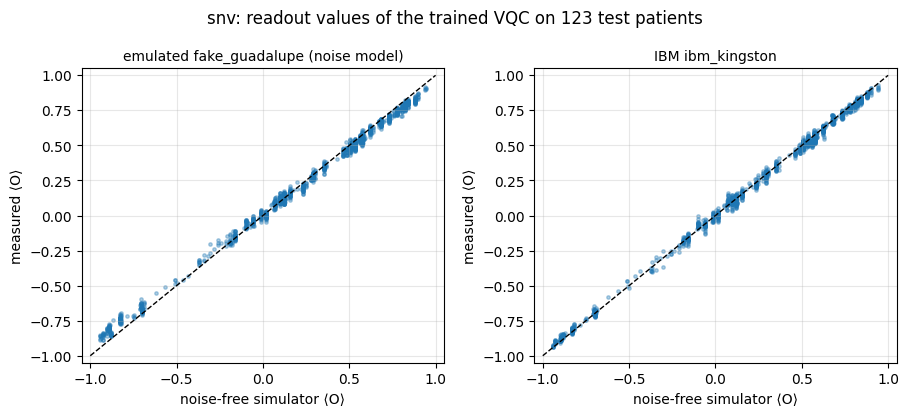

In [74]:
# %% ---------------- CELL E4 — F1 on hardware vs the noise-free simulator ----------------
sel = [MEM[m] for m in HW_MEMBERS]; Z_SIM = [z0[m] for m in HW_MEMBERS]
P_SIM = ensemble_probs(sel, Z_SIM); pred_sim = P_SIM.argmax(1)
rows = []


def add_row(label, pred, z=None, models=None):
    lo, hi = ci(y_te, pred); r = {"setting": label, "models": len(HW_MEMBERS) if models is None else models, "test_macro_f1": mf1(y_te, pred), "ci_low": lo, "ci_high": hi}
    if z is not None:
        d, dlo, dhi, pv = paired(y_te, pred, pred_sim)
        r.update({"minus_noise_free": d, "diff_ci_low": dlo, "diff_ci_high": dhi, "p": pv,
                  "same_prediction_as_noise_free": float((pred == pred_sim).mean()),
                  "readout_mean_abs_error": float(np.mean([np.abs(z[m] - z0[m]).mean() for m in HW_MEMBERS])),
                  "readout_correlation": float(np.corrcoef(np.concatenate([z[m].ravel() for m in HW_MEMBERS]),
                                                           np.concatenate([z0[m].ravel() for m in HW_MEMBERS]))[0, 1])})
    rows.append(r)


add_row("noise-free simulator (same models)", pred_sim)
for label, z in HW_RUNS.items():
    add_row(label, ensemble_probs(sel, [z[m] for m in HW_MEMBERS]).argmax(1), z)
if len(HW_MEMBERS) < len(MEM):
    add_row(f"reference: full {len(MEM)}-model ensemble, simulator", VQC_TEST_RERUN.argmax(1), models=len(MEM))
try:
    lr = C2[C2.model.str.startswith("LR (same")].iloc[0]
    rows.append({"setting": "reference: LR on the same features (Part C)", "test_macro_f1": lr.test_macro_f1, "ci_low": lr.ci_low, "ci_high": lr.ci_high})
except Exception:
    pass
E4 = pd.DataFrame(rows); E4.to_csv(os.path.join(E_DIR, "E4_hardware_f1.csv"), index=False); display(E4.round(3))

if HW_RUNS:
    fig, axs = plt.subplots(1, len(HW_RUNS), figsize=(4.6 * len(HW_RUNS), 4.2), squeeze=False)
    for ax, (label, z) in zip(axs[0], HW_RUNS.items()):
        a = np.concatenate([z0[m].ravel() for m in HW_MEMBERS]); b = np.concatenate([z[m].ravel() for m in HW_MEMBERS])
        ax.scatter(a, b, s=6, alpha=.35); ax.plot([-1, 1], [-1, 1], "k--", lw=1)
        ax.set_xlabel("noise-free simulator ⟨O⟩"); ax.set_ylabel("measured ⟨O⟩"); ax.set_title(label, fontsize=10)
        ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05); ax.grid(alpha=.3)
    fig.suptitle(f"{MODALITY}: readout values of the trained VQC on {B_TE} test patients"); fig.tight_layout()
    fig.savefig(os.path.join(E_DIR, "figE_hardware_vs_simulator.png"), dpi=300); plt.show()


In [75]:
# %% ---------------- CELL E5 — what to write in the paper ----------------
r0 = E4.iloc[0]
print(f"• {MODALITY}: trained VQC ({n_q} qubits; {RES_E.two_qubit_gates.iloc[0]} native two-qubit gates and depth "
      f"{RES_E.depth.iloc[0]} after compilation for {BK}) evaluated on the {B_TE} held-out test patients, "
      f"{len(HW_MEMBERS)} model(s), {SHOTS} shots per patient.")
print(f"• Noise-free simulator: test macro-F1 {r0.test_macro_f1:.3f} (95% CI {r0.ci_low:.3f}–{r0.ci_high:.3f}).")
for r in E4.iloc[1:].itertuples():
    if isinstance(getattr(r, "minus_noise_free", None), float) and not np.isnan(r.minus_noise_free):
        print(f"• {r.setting}: test macro-F1 {r.test_macro_f1:.3f} (95% CI {r.ci_low:.3f}–{r.ci_high:.3f}); difference from "
              f"noise-free {r.minus_noise_free:+.3f} (95% CI {r.diff_ci_low:+.3f} to {r.diff_ci_high:+.3f}, p = {r.p:.3f}); "
              f"same predicted class for {100 * r.same_prediction_as_noise_free:.1f}% of patients; readout correlation "
              f"{r.readout_correlation:.3f}.")
if os.path.exists(JOB_FILE):
    m = json.load(open(JOB_FILE))
    print(f"• Methods detail: IBM job {m.get('job_id')} on {m.get('backend')} ({m.get('finished', m.get('submitted'))}); "
          f"Estimator resilience level {m.get('resilience_level')}, dynamical decoupling {m.get('dynamical_decoupling')}, "
          f"gate twirling {m.get('gate_twirling')}; QPU time {m.get('qpu_seconds')} s. Calibration of the qubits used: E2_calibration.csv.")
print("• Training was done on a noise-free simulator; only inference was run on the quantum device.")
print("\nSaved in", E_DIR, ":", sorted(os.listdir(E_DIR)))

• snv: trained VQC (11 qubits; 30 native two-qubit gates and depth 27 after compilation for ibm_kingston) evaluated on the 123 held-out test patients, 1 model(s), 2048 shots per patient.
• Noise-free simulator: test macro-F1 0.544 (95% CI 0.450–0.627).
• emulated fake_guadalupe (noise model): test macro-F1 0.536 (95% CI 0.441–0.620); difference from noise-free -0.008 (95% CI -0.027 to +0.000, p = 0.722); same predicted class for 99.2% of patients; readout correlation 0.999.
• IBM ibm_kingston: test macro-F1 0.544 (95% CI 0.450–0.627); difference from noise-free +0.000 (95% CI +0.000 to +0.000, p = 1.000); same predicted class for 100.0% of patients; readout correlation 0.999.
• Methods detail: IBM job dbo3f58qtr0c73aduimg on None (2026-11-11 19:03:24); Estimator resilience level None, dynamical decoupling None, gate twirling None; QPU time 85.0 s. Calibration of the qubits used: E2_calibration.csv.
• Training was done on a noise-free simulator; only inference was run on the quantum dev

,modality,device,test_patients,flipped,flipped_pct,median_margin_flipped,median_margin_unflipped,p_flipped_have_smaller_margin,flips_in_lowest_margin_quarter_pct,max_margin_of_a_flip,correct_to_wrong,wrong_to_correct,wrong_to_wrong
0,snv,ibm_kingston,123,0,0.0,NaN,0.266,NaN,0.0,NaN,0,0,0


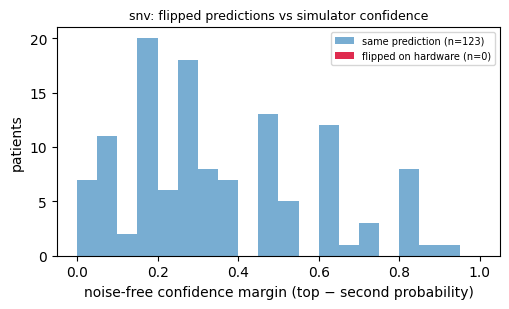

• snv: 0 of 123 test patients (0.0%) changed prediction on hardware.
Saved: /kaggle/working/hw_probs_snv.csv and E6_flip_analysis.csv, E6_flipped_patients.csv, figE6_flip_margin.png in /kaggle/working/partE_snv


In [76]:
# %% ---------------- CELL E6 — export the hardware probabilities for fusion + flipped-prediction analysis ----------------
# Needs the IBM result in this session: E0 with SUBMIT_TO_IBM = False and RETRIEVE_JOB_ID = "<this modality's job ID>",
# then E0-E4 (or Run All). Uses no QPU time. Writes hw_probs_<modality>.csv (for the fusion notebook) and
# E6_flip_analysis.csv / E6_flipped_patients.csv (which patients changed prediction on hardware, and how sure the model was).
from scipy.stats import mannwhitneyu
hw_key = next((k for k in HW_RUNS if k.startswith("IBM ")), None)
assert hw_key is not None, "No IBM hardware result in this session: set RETRIEVE_JOB_ID in E0 (SUBMIT_TO_IBM = False) and run E0-E4 first."
P_HW = ensemble_probs(sel, [HW_RUNS[hw_key][m] for m in HW_MEMBERS])      # the same model(s) on IBM hardware
P_NF = ensemble_probs(sel, Z_SIM)                                         # the same model(s), noise-free simulator
assert len(te_ids) == len(P_HW) == len(y_te), "test-patient order mismatch"
parts = []
for kind, P in [("hardware", P_HW), ("noise_free_same_model", P_NF)]:
    d = pd.DataFrame(P, columns=CLASSES); d.insert(0, "kind", kind); d.insert(0, "patient", [str(p) for p in te_ids])
    parts.append(d)
hw_file = os.path.join(OUTPUT_DIR, f"hw_probs_{MODALITY}.csv")
pd.concat(parts, ignore_index=True).to_csv(hw_file, index=False)

# ---- flipped predictions vs the simulator's confidence margin (top probability minus second) ----
srt = np.sort(P_NF, 1); margin = srt[:, -1] - srt[:, -2]
pred_nf, pred_hw = P_NF.argmax(1), P_HW.argmax(1); flip = pred_hw != pred_nf
q1 = margin <= np.quantile(margin, 0.25)
p_mw = float(mannwhitneyu(margin[flip], margin[~flip], alternative="less").pvalue) if 0 < flip.sum() < len(flip) else np.nan
FLIP = pd.DataFrame([{
    "modality": MODALITY, "device": hw_key.replace("IBM ", ""), "test_patients": len(flip), "flipped": int(flip.sum()),
    "flipped_pct": 100 * flip.mean(),
    "median_margin_flipped": float(np.median(margin[flip])) if flip.any() else np.nan,
    "median_margin_unflipped": float(np.median(margin[~flip])),
    "p_flipped_have_smaller_margin": p_mw,
    "flips_in_lowest_margin_quarter_pct": 100 * (flip & q1).sum() / max(flip.sum(), 1),
    "max_margin_of_a_flip": float(margin[flip].max()) if flip.any() else np.nan,
    "correct_to_wrong": int((flip & (pred_nf == y_te)).sum()), "wrong_to_correct": int((flip & (pred_hw == y_te)).sum()),
    "wrong_to_wrong": int((flip & (pred_nf != y_te) & (pred_hw != y_te)).sum())}])
FLIP.to_csv(os.path.join(E_DIR, "E6_flip_analysis.csv"), index=False)
pd.DataFrame({"patient": [str(p) for p in te_ids], "true": [CLASSES[i] for i in y_te],
              "pred_noise_free": [CLASSES[i] for i in pred_nf], "pred_hardware": [CLASSES[i] for i in pred_hw],
              "margin_noise_free": margin, "flipped": flip}).to_csv(os.path.join(E_DIR, "E6_flipped_patients.csv"), index=False)
display(FLIP.round(3))

fig, ax = plt.subplots(figsize=(5.2, 3.2))
bins = np.linspace(0, 1, 21)
ax.hist(margin[~flip], bins=bins, alpha=.6, label=f"same prediction (n={int((~flip).sum())})")
ax.hist(margin[flip], bins=bins, alpha=.9, label=f"flipped on hardware (n={int(flip.sum())})", color="crimson")
ax.set_xlabel("noise-free confidence margin (top − second probability)"); ax.set_ylabel("patients"); ax.legend(fontsize=7)
ax.set_title(f"{MODALITY}: flipped predictions vs simulator confidence", fontsize=9); fig.tight_layout()
fig.savefig(os.path.join(E_DIR, "figE6_flip_margin.png"), dpi=200); plt.show()
r = FLIP.iloc[0]
print(f"• {MODALITY}: {r.flipped} of {r.test_patients} test patients ({r.flipped_pct:.1f}%) changed prediction on hardware"
      + (f"; their median noise-free margin was {r.median_margin_flipped:.3f} vs {r.median_margin_unflipped:.3f} for the others "
         f"(one-sided Mann–Whitney p = {r.p_flipped_have_smaller_margin:.3g}), the largest margin of a flipped patient was "
         f"{r.max_margin_of_a_flip:.3f}; flips: {r.correct_to_wrong} correct→wrong, {r.wrong_to_correct} wrong→correct, "
         f"{r.wrong_to_wrong} wrong→wrong." if r.flipped else "."))
print("Saved:", hw_file, "and E6_flip_analysis.csv, E6_flipped_patients.csv, figE6_flip_margin.png in", E_DIR)